# Typing out a live call: what an update costs, and what the pacing spends

A tool call's code arrives in bursts (the worker flushes at most every 90 ms; a hub relays slower), and the sidebar
types it out at an even pace instead (`useReveal`, `src/sidebar/transcript/live-call.tsx`). Every tick re-renders the
cell, and the panel's `highlight()` runs highlight.js over the WHOLE text each time. Two questions:

1. What does one update cost, by size and language? (highlight.js, plus the DOM swap and layout.)
2. Does the pacing in `reveal.ts` keep the reveal within its share of the main thread (`budgetShare`), and how far
   does it trail the stream?

The cost rows are measured by `highlight-cost.mjs`: Node for highlight.js, Chromium for the DOM. Preact's own diff is
not in them; the component measures its real render cost at run time and paces from that, so these rows set the
constants, not the live behaviour.

In [1]:
import json, re, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wmlnb

HERE = wmlnb.ROOT / "notebooks" / "ui"
EXTRACT = HERE / "data" / "live-call-reveal" / "costs.json"
pd.set_option("display.width", 160)

def measure():
    out = subprocess.run(["node", "--import", "tsx", str(HERE / "highlight-cost.mjs")], cwd=wmlnb.ROOT,
                         capture_output=True, text=True, check=True).stdout
    body = json.loads(out)
    return [{**r, "node": body["node"], "reps": body["reps"]} for r in body["rows"]]

rows = wmlnb.extract(EXTRACT, measure, source={"script": "notebooks/ui/highlight-cost.mjs", "machine": "the laptop that ran it"})
wmlnb.provenance(EXTRACT)

[{'extract': 'notebooks/ui/data/live-call-reveal/costs.json',
  'sha256': 'f6fb646185142435',
  'rows': 16,
  'extracted_at': '2026-10-21T13:02:02+00:00',
  'commit': '271466d3575c',
  'machine': 'the laptop that ran it',
  'script': 'notebooks/ui/highlight-cost.mjs'}]

## 1. One update, by size

`total` is highlight.js plus the plain DOM swap; `total_numbered` uses the line-number gutter instead (the split into
lines plus one element per line). Milliseconds, medians of 30 runs.

In [2]:
df = pd.DataFrame(rows)
df["total"] = df.hljs_ms + df.dom_ms
df["total_numbered"] = df.hljs_ms + df.gutter_split_ms + df.dom_numbered_ms
df[["lang", "chars", "lines", "hljs_ms", "hljs_p95_ms", "dom_ms", "total", "total_numbered"]].round(2)

,lang,chars,lines,hljs_ms,hljs_p95_ms,dom_ms,total,total_numbered
0,python,250,7,0.01,0.05,0.1,0.11,0.11
1,python,500,16,0.01,0.02,0.1,0.11,0.22
2,python,1000,34,0.10,0.11,0.2,0.30,0.51
3,python,2000,59,0.23,0.27,0.5,0.73,1.05
4,python,5000,140,1.07,4.78,1.5,2.57,3.17
5,python,10000,272,1.36,1.84,3.1,4.46,6.20
6,python,20000,534,3.13,4.33,6.9,10.03,12.63
7,python,40000,1067,4.49,6.67,16.1,20.59,24.55
8,javascript,250,3,0.05,0.07,0.1,0.15,0.15
9,javascript,500,6,0.10,0.12,0.1,0.20,0.20


Cost is close to linear in the text's length, so a slope per language summarises it: milliseconds per 1000 characters.

In [3]:
fit = []
for lang, g in df.groupby("lang"):
    for col in ["total", "total_numbered"]:
        k, b = np.polyfit(g.chars / 1000, g[col], 1)
        r2 = np.corrcoef(g.chars, g[col])[0, 1] ** 2
        fit.append({"lang": lang, "path": col, "ms_per_1k_chars": k, "intercept_ms": b, "r2": r2})
fit = pd.DataFrame(fit).round(3)
fit

,lang,path,ms_per_1k_chars,intercept_ms,r2
0,javascript,total,0.875,-0.475,0.998
1,javascript,total_numbered,0.893,-0.192,1.000
2,python,total,0.517,-0.228,0.999
3,python,total_numbered,0.619,-0.036,1.000


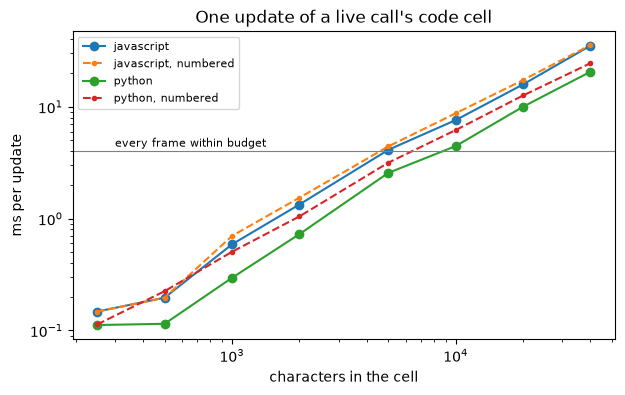

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for (lang, g) in df.groupby("lang"):
    ax.plot(g.chars, g.total, marker="o", label=f"{lang}")
    ax.plot(g.chars, g.total_numbered, marker=".", linestyle="--", label=f"{lang}, numbered")
ax.axhline(16 * 0.25, color="grey", linewidth=0.8); ax.text(300, 16 * 0.25 * 1.1, "every frame within budget", fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("characters in the cell"); ax.set_ylabel("ms per update")
ax.legend(fontsize=8); ax.set_title("One update of a live call's code cell")
plt.show()

## 2. The constants, read from `reveal.ts`

Read from the source, so the thresholds below are the ones that ship.

In [5]:
src = (wmlnb.ROOT / "src" / "sidebar" / "transcript" / "reveal.ts").read_text()
C = {k: float(v) for k, v in re.findall(r"(\w+): ([\d.]+),", src.split("export const REVEAL = {")[1].split("};")[0])}
C

{'minGapMs': 60.0,
 'maxGapMs': 400.0,
 'jumpChars': 4000.0,
 'maxCostMs': 30.0,
 'budgetShare': 0.25,
 'frameMs': 16.0}

In [6]:
def chars_at(ms, lang, col="total"):
    f = fit[(fit.lang == lang) & (fit.path == col)].iloc[0]
    return max(0, (ms - f.intercept_ms) / f.ms_per_1k_chars * 1000)

every_frame = C["frameMs"] * C["budgetShare"]
pd.DataFrame([{"lang": lang, "path": col,
               f"typed every frame up to (cost <= {every_frame:g} ms)": round(chars_at(every_frame, lang, col)),
               f"not typed above (cost > {C['maxCostMs']:g} ms)": round(chars_at(C["maxCostMs"], lang, col))}
              for lang in ["python", "javascript"] for col in ["total", "total_numbered"]])

,lang,path,typed every frame up to (cost <= 4 ms),not typed above (cost > 30 ms)
0,python,total,8178,58468
1,python,total_numbered,6520,48523
2,javascript,total,5114,34829
3,javascript,total_numbered,4694,33810


## 3. The pacing, simulated

A Python copy of the rules in `reveal.ts` (`nextGap`, `revealRate`, `advance`, `tickDelay`, the jump), run against a
stream that arrives in bursts every 90 ms at a model's pace, with each render costing what section 1 measured for the
cell's size at that moment. It reports the share of the main thread that rendering on each arrival takes anyway
(`arrival_share`, the cost without the reveal), what the reveal's own ticks add (`reveal_share`, held to
`budgetShare`) and how often they come, and the longest any character waited between arriving and being shown. `tests/live-call-reveal.test.mjs`
holds the TypeScript rules to the same properties.

In [7]:
def cost_ms(chars, lang):
    f = fit[(fit.lang == lang) & (fit.path == "total")].iloc[0]
    return max(0.05, f.intercept_ms + f.ms_per_1k_chars * chars / 1000)

def simulate(final_chars, lang, chars_per_s=400, flush_ms=90):
    clamp = lambda g: min(C["maxGapMs"], max(C["minGapMs"], g))
    t, arrived, shown, gap, rate, at, ticked, cost = 0.0, 0, 0, 90.0, 0.0, None, 0.0, 0.0
    arrivals = []                      # (time, characters arrived by then): when each character became showable
    base, extra, ticks, worst_lag = 0.0, 0.0, 0, 0.0
    next_flush, next_tick = flush_ms, None
    while shown < final_chars or arrived < final_chars:
        tick = next_tick is not None and next_tick < next_flush
        if not tick:
            t = next_flush; next_flush += flush_ms
            new = min(final_chars, int(chars_per_s * t / 1000))
            if new == arrived: continue
            prev, arrived = arrived, new; arrivals.append((t, arrived))
            if at is not None: gap = gap * 0.7 + clamp(t - at) * 0.3
            at = t
            if shown >= prev: ticked = t       # idle until now: the next step is measured from this arrival
            if (arrived - shown > C["jumpChars"]) or cost > C["maxCostMs"]: shown = arrived
            rate = max(0, arrived - shown) / clamp(gap)
        else:
            t = next_tick
            shown = min(arrived, shown + max(1, round(rate * (t - ticked))))
            ticked = t
        c = cost_ms(shown, lang); cost = c if not cost else cost * 0.7 + c * 0.3
        # An arrival re-renders the cell with or without the reveal; only the ticks between arrivals are its cost.
        if tick: extra += c; ticks += 1
        else: base += cost_ms(arrived, lang)
        if shown < arrived:
            oldest = next(ta for ta, n in arrivals if n > shown)   # when the first unshown character arrived
            worst_lag = max(worst_lag, t - oldest)
            # One pending tick at a time: an arrival never postpones it (as the component's timer).
            if tick or next_tick is None: next_tick = t + max(C["frameMs"], cost / C["budgetShare"])
        else:
            next_tick = None
    return {"lang": lang, "final_chars": final_chars, "seconds": round(t / 1000, 1),
            "arrival_share": round(base / t, 3), "reveal_ticks_per_s": round(ticks / (t / 1000), 1),
            "reveal_share": round(extra / t, 3), "worst_lag_ms": round(worst_lag)}

sim = pd.DataFrame([simulate(n, lang) for lang in ["python", "javascript"] for n in [1000, 3000, 10000, 20000, 40000]])
sim

,lang,final_chars,seconds,arrival_share,reveal_ticks_per_s,reveal_share,worst_lag_ms
0,python,1000,2.6,0.001,59.1,0.006,90
1,python,3000,7.6,0.006,60.4,0.035,96
2,python,10000,25.1,0.026,59.7,0.138,90
3,python,20000,50.1,0.055,46.5,0.189,90
4,python,40000,100.2,0.112,31.2,0.212,90
5,javascript,1000,2.6,0.001,59.1,0.007,90
6,javascript,3000,7.6,0.010,60.4,0.054,96
7,javascript,10000,25.1,0.044,51.1,0.173,90
8,javascript,20000,50.1,0.092,35.1,0.202,90
9,javascript,40000,100.1,0.190,20.8,0.171,90


In [8]:
assert (sim.reveal_share <= C["budgetShare"]).all(), "the reveal spent more than its share"
assert (sim.worst_lag_ms <= C["maxGapMs"]).all(), "a character waited longer than the longest gap to be shown"
"within budget and lag bounds"

'within budget and lag bounds'